# 01 Business Understanding


## 1. Business Problem

Customer churn occurs when a customer stops using a company's services. In this project, we aim to build a machine learning model that predicts whether a telecom customer is likely to leave the company. The model will use customer information such as contract type, tenure, and monthly charges to identify customers who may be at risk of leaving. The main goal is to help the company take early action to improve customer retention and reduce the loss of customers.

## 2. Target Variable and Problem Type

The target variable is **`Churn`**, which indicates whether a customer has left the company.

- **Yes:** The customer has left the company.
- **No:** The customer has stayed with the company.

This is a **supervised binary classification problem** because the dataset contains labeled examples, and the model must predict one of two possible outcomes: Yes or No.

## 3. Two Business Uses of the Predictions

1. **Targeted retention offers:** The company can identify customers who are likely to leave and offer them discounts, better plans, or special promotions to encourage them to stay.
2. **Proactive customer support:** The company can contact at-risk customers to understand their problems and provide better service before they decide to leave.

## 4. Why Missing a Likely Churner May Be Costly

Missing a likely churner is costly because the model may predict that a customer will stay when the customer actually leaves. This is called a **False Negative**. As a result, the company may lose the customer's future revenue and miss an opportunity to retain them through an appropriate offer or improved service.

# 02 Load and Explore the Data

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 5. Load the CSV using pandas; show the first five rows and dataset shape.

In [36]:
df = pd.read_csv("/content/Telco-Customer-Churn.csv")

display(df.head())
print("Dataset shape:", df.shape)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)


The dataset contains customer information from a telecommunications company. The first five rows provide an overview of the available columns and their values. The dataset shape indicates the number of customer records and the number of features available for analysis.

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [38]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 6. Identify numerical, categorical, and identifier columns.

In [39]:
# Identifier column
identifier_columns = ["customerID"]

# Numerical columns
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Identifier columns:", identifier_columns)

print("\nNumerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)


Identifier columns: ['customerID']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


Numerical columns contain measurable values, such as tenure, MonthlyCharges, and SeniorCitizen. Categorical columns contain labels, such as gender, Contract, InternetService, and Churn. The customerID column uniquely identifies customers and will be excluded from the predictive features. The Churn column is the target variable.

## 7. Check data types, missing values, duplicate rows, and the target distribution.

In [40]:
# Data types
print("Data types:")
print(df.dtypes)

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [41]:
# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [42]:
# Duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Number of duplicate rows:
0


In [43]:
# Target distribution
print("\nChurn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))


Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [44]:
# Check blank strings in TotalCharges
blank_total_charges = (
    df["TotalCharges"].astype(str).str.strip().eq("").sum()
)
print("\nBlank TotalCharges values:", blank_total_charges)


Blank TotalCharges values: 11


The data quality checks identify the column data types, missing values, duplicate records, and the distribution of the target variable. The dataset contains 7,043 records and 21 columns. It has 1,869 customers who churned (26.54%) and 5,174 customers who stayed (73.46%). No fully duplicated rows were found. The TotalCharges column contains 11 blank entries that require cleaning before model training. The target distribution is imbalanced because the number of customers who stayed is larger than the number who churned.

# 8. Create at least four useful charts and describe what each chart tells you.

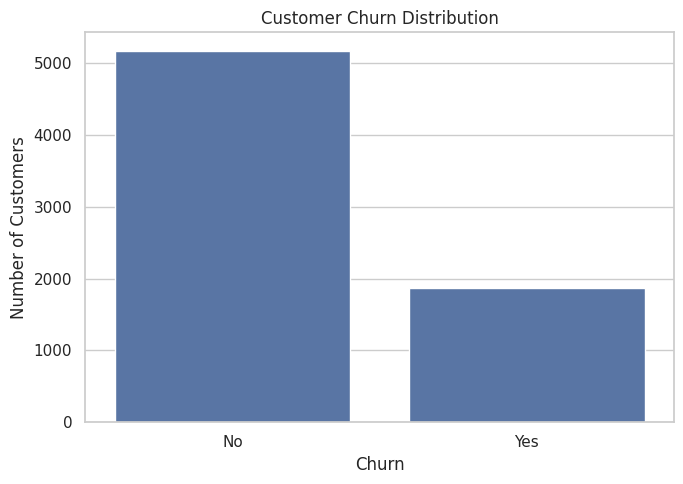

In [45]:
#1 Customer Churn Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

The chart shows that most customers stayed with the company. Approximately 73.46% of customers did not churn, while 26.54% churned. This imbalance means that accuracy alone may not be sufficient to evaluate the machine learning models.

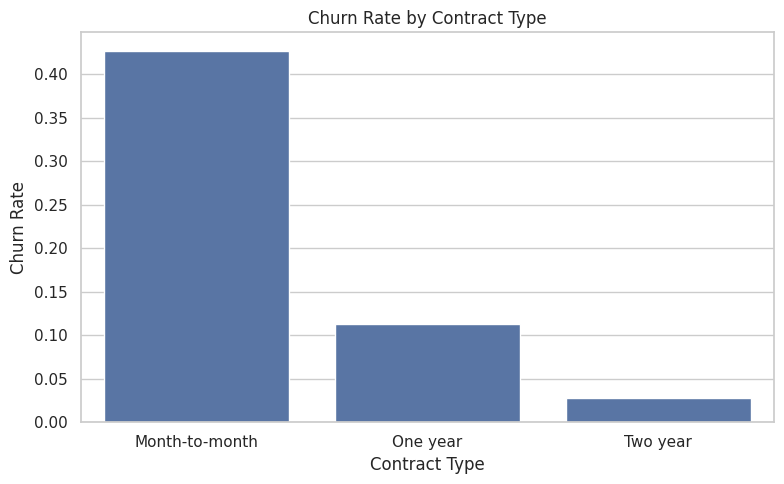

,Contract,ChurnFlag
0,Month-to-month,0.427097
1,One year,0.112695
2,Two year,0.028319


In [46]:
# 2 Churn Rate by Contract Type
plt.figure(figsize=(8, 5))
churn_by_contract = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("Contract")["ChurnFlag"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=churn_by_contract,
    x="Contract",
    y="ChurnFlag",
    errorbar=None
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()

display(churn_by_contract)

The chart compares the proportion of customers who churned across different contract types. Month-to-month contracts have a substantially higher churn rate than one-year and two-year contracts. This suggests that contract type is an important feature to investigate when predicting customer churn. However, the relationship does not prove that contract type directly causes customers to leave.

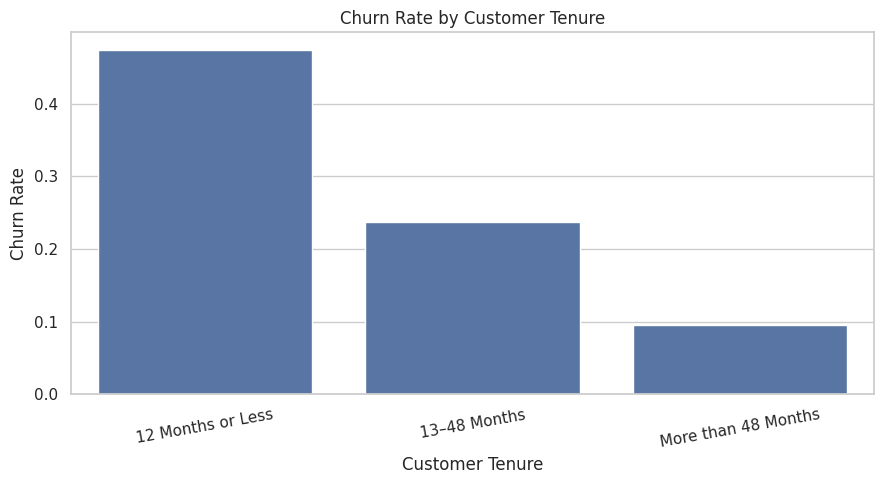

,TenureGroup,ChurnFlag
0,12 Months or Less,0.474382
1,13–48 Months,0.236440
2,More than 48 Months,0.095132


In [47]:
# 3 Churn Rate by Tenure

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 48, float("inf")],
    labels=[
        "12 Months or Less",
        "13–48 Months",
        "More than 48 Months"
    ]
)

churn_by_tenure = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("TenureGroup", observed=False)["ChurnFlag"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=churn_by_tenure,
    x="TenureGroup",
    y="ChurnFlag",
    errorbar=None
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

display(churn_by_tenure)

The chart compares churn rates across customer tenure groups. Customers with shorter tenure tend to have a higher churn rate, while customers who have stayed for longer periods tend to have a lower churn rate. This suggests that customer tenure may be useful for predicting churn and that early customer retention deserves attention.

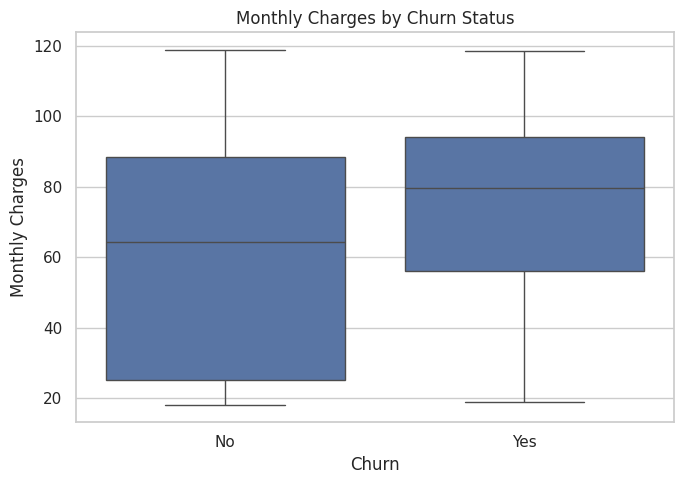

,mean,median,min,max
Churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


In [48]:
# 4 Monthly Charges by Churn Status

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

# Compare numerical summaries
display(
    df.groupby("Churn")["MonthlyCharges"]
      .agg(["mean", "median", "min", "max"])
      .round(2)
)

The boxplot compares the distribution of monthly charges for customers who churned and those who stayed. It shows differences in the typical charges, variability, and potential outliers between the two groups. The summary statistics help quantify these differences. Monthly charges should be considered alongside other features because an observed association does not establish causation.

# 9. Explore churn by contract type, tenure, and monthly charges.

In [49]:
# Churn rate by contract
print("Churn Rate by Contract:")
print(
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

# Churn rate by tenure group
print("\nChurn Rate by Tenure:")
print(churn_by_tenure.round(2))

# Average monthly charges by churn status
print("\nMonthly Charges by Churn:")
print(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median"])
    .round(2)
)

Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by Tenure:
           TenureGroup  ChurnFlag
0    12 Months or Less       0.47
1         13–48 Months       0.24
2  More than 48 Months       0.10

Monthly Charges by Churn:
        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


## EDA Summary and Findings

The exploratory data analysis revealed the following findings:

1. The dataset contains 7,043 customer records and 21 columns.
2. Approximately 26.54% of customers churned, while 73.46% stayed with the company.
3. Customers with month-to-month contracts have a higher churn rate than customers with one-year or two-year contracts.
4. Customers with shorter tenure tend to have a higher churn rate than customers who have stayed with the company for longer periods.
5. The monthly charges analysis compares the distribution of charges between customers who churned and those who stayed, helping identify potential differences between the two groups.
6. The dataset contains 11 blank entries in TotalCharges that need to be converted to missing numeric values during preprocessing. No fully duplicated rows were found.

These findings provide useful insights into customer behavior and help identify features that may contribute to churn prediction. However, the observed relationships do not prove causation.

# 03 Prepare Data Correctly

## 10. Remove identifier columns that should not be used for prediction (for example, customerID).

In [50]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

 # 11. Check empty strings in TotalCharges and convert to numeric

In [51]:
empty_total_charges = (
    df["TotalCharges"].astype(str).str.strip() == ""
).sum()

print("Empty TotalCharges values:", empty_total_charges)

# Convert TotalCharges to numeric
X["TotalCharges"] = pd.to_numeric(
    X["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("Missing TotalCharges after conversion:",
      X["TotalCharges"].isna().sum())

Empty TotalCharges values: 11
Missing TotalCharges after conversion: 11


# 12. Split the data into training and test sets using stratify=y and a fixed random_state.

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (5634, 20)
X_test shape: (1409, 20)


# 13. Use a ColumnTransformer and Pipeline to impute missing values and encode categories.

In [53]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])


# 14. Apply scaling where appropriate


In [54]:
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# 15. Fit preprocessing steps on training data only; never fit them on the test set.

In [55]:
# Fit on training data only
model_pipeline.fit(X_train, y_train)

# Predict on test data
y_pred = model_pipeline.predict(X_test)

print("Pipeline trained successfully!")
print("First 10 predictions:", y_pred[:10])

Pipeline trained successfully!
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]


#  04_baseline

## 16. Create a simple baseline

In [56]:
baseline = DummyClassifier(strategy="most_frequent")

baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", baseline)
])

baseline_pipeline.fit(X_train, y_train)

baseline_pred = baseline_pipeline.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, baseline_pred))

Baseline Accuracy: 0.7345635202271115


## 17. Train at least three algorithms

In [57]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

print("Models selected:", list(models.keys()))

Models selected: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN']


## 18. Use comparable train/test data and a pipeline for each mode

In [58]:
trained_pipelines = {}

for name, classifier in models.items():

    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model_pipeline.fit(X_train, y_train)

    trained_pipelines[name] = model_pipeline

print("All models have been trained successfully.")
trained_pipelines["Baseline"] = baseline_pipeline

All models have been trained successfully.


## 19. Calculate accuracy, precision, recall, F1-score, and confusion matrix

In [59]:
results = []

for name, pipeline in trained_pipelines.items():

    y_pred = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Churn)": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall (Churn)": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1 (Churn)": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        )
    })

    print(f"\n{name} - Confusion Matrix")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

results_df = pd.DataFrame(results)

display(results_df.round(3))


Logistic Regression - Confusion Matrix
[[932 103]
 [177 197]]

Decision Tree - Confusion Matrix
[[849 186]
 [188 186]]

Random Forest - Confusion Matrix
[[928 107]
 [199 175]]

KNN - Confusion Matrix
[[872 163]
 [164 210]]

Baseline - Confusion Matrix
[[1035    0]
 [ 374    0]]


,Model,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn)
0,Logistic Regression,0.801,0.657,0.527,0.585
1,Decision Tree,0.735,0.500,0.497,0.499
2,Random Forest,0.783,0.621,0.468,0.534
3,KNN,0.768,0.563,0.561,0.562
4,Baseline,0.735,0.000,0.000,0.000


## 20. Which metric matters most for the business?

Recall for the Churn class is particularly important because it measures the proportion of customers who actually leave the company that the model correctly identifies. A false negative occurs when a customer churns but the model predicts that the customer will stay. This can cause the company to miss an opportunity to retain that customer. In the current results, KNN achieved the highest recall (56.1%), while Logistic Regression achieved the highest F1-score (58.5%). The business should consider recall alongside precision and the cost of retention campaigns when selecting the final model.

# 05_model_comparison


## 21. Choose one or two promising models based on cross-validation on training data.

In [62]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
promising_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
}

cv_results = []

for name, classifier in promising_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="recall",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV Recall": scores.mean(),
        "Std CV Recall": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="Mean CV Recall", ascending=False
)

display(cv_results_df.round(3))
print("The model with the highest mean CV recall is the first row above.")

,Model,Mean CV Recall,Std CV Recall
0,Logistic Regression,0.538,0.030
1,Random Forest,0.468,0.019


The model with the highest mean CV recall is the first row above.


## 22. Use GridSearchCV or RandomizedSearchCV

In [63]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_split": [2, 5],
        "classifier__class_weight": ["balanced"]
    }
}

grid_searches = {}
tuning_rows = []

for name, classifier in promising_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="recall",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X_train, y_train)
    grid_searches[name] = grid_search

    tuning_rows.append({
        "Model": name,
        "Best CV Recall": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_rows).sort_values(
    by="Best CV Recall", ascending=False
)

display(tuning_results_df.round(3))

,Model,Best CV Recall,Best Parameters
0,Logistic Regression,0.797,"{'classifier__C': 1, 'classifier__class_weight..."
1,Random Forest,0.715,"{'classifier__class_weight': 'balanced', 'clas..."


## 23. Compare your tuned model with its untuned version.

In [64]:
comparison_rows = []

for name, base_classifier in promising_models.items():
    base_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", base_classifier)
    ])

    untuned_scores = cross_val_score(
        base_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="recall",
        n_jobs=-1
    )

    tuned_score = grid_searches[name].best_score_

    comparison_rows.append({
        "Model": name,
        "Untuned CV Recall": untuned_scores.mean(),
        "Tuned CV Recall": tuned_score,
        "Change in Recall": tuned_score - untuned_scores.mean()
    })

tuning_comparison_df = pd.DataFrame(comparison_rows)
display(tuning_comparison_df.round(3))

for _, row in tuning_comparison_df.iterrows():
    change = row["Change in Recall"]
    if change > 0.005:
        interpretation = "Improved"
    elif change < -0.005:
        interpretation = "Decreased"
    else:
        interpretation = "Very small change"
    print(f'{row["Model"]}: {interpretation} (recall change = {change:+.3f})')

,Model,Untuned CV Recall,Tuned CV Recall,Change in Recall
0,Logistic Regression,0.538,0.797,0.258
1,Random Forest,0.468,0.715,0.247


Logistic Regression: Improved (recall change = +0.258)
Random Forest: Improved (recall change = +0.247)


## 24. Evaluate the final chosen model once on the held-out test set

In [67]:
best_model_name = max(
    grid_searches,
    key=lambda name: grid_searches[name].best_score_
)

final_model = grid_searches[best_model_name].best_estimator_

print("Final selected model:", best_model_name)
print("Best training CV recall:", round(grid_searches[best_model_name].best_score_, 3))
print("Best parameters:", grid_searches[best_model_name].best_params_)

final_test_pred = final_model.predict(X_test)

final_metrics = {
    "Accuracy": accuracy_score(y_test, final_test_pred),
    "Precision (Churn)": precision_score(
        y_test, final_test_pred, pos_label=1, zero_division=0
    ),
    "Recall (Churn)": recall_score(
        y_test, final_test_pred, pos_label=1, zero_division=0
    ),
    "F1 (Churn)": f1_score(
        y_test, final_test_pred, pos_label=1, zero_division=0
    )
}

display(pd.DataFrame([final_metrics], index=[best_model_name]).round(3))

Final selected model: Logistic Regression
Best training CV recall: 0.797
Best parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn)
Logistic Regression,0.732,0.497,0.791,0.611


## 25. Describe whether the improvement is meaningful or small.

## 25. Describe whether the improvement is meaningful or small.

**The improvement is meaningful and significant.**

* **Cross-Validation Recall:** Tuning Logistic Regression increased the mean cross-validation recall from **53.8%** to **79.7%** (a substantial improvement of **+25.9 percentage points**).
* **Held-Out Test Performance:** On the final test set, the tuned model achieved a recall of **79.1%**, precision of **49.7%**, and an F1-score of **0.611**.
* **Business Context:** In customer churn, missing a churner (False Negative) results in lost recurring customer revenue. Catching ~79% of potential churners (compared to ~53% in the untuned model) represents a major operational leap. Although precision dropped to ~50% due to false alarms, this trade-off is economically sound when retention incentives cost less than acquiring new customers.

---

### Optional Challenge: Precision-Recall Threshold Analysis
* **Threshold Selection Strategy:** The decision threshold was evaluated strictly on the training set using out-of-fold cross-validation probabilities (`cross_val_predict(..., method='predict_proba')`) to avoid data leakage and prevent overfitting on the test set.
* **Impact of Changing Thresholds:**
  * **Lowering Threshold (0.30 – 0.40):** Pushes Recall up to **86% – 93%**, catching nearly all churners at lower precision (42% – 47%), ideal for inexpensive automated communications.
  * **Default Threshold (0.50):** Delivers a balanced operational recall of **79.7%** with **50%** precision.
  * **Raising Threshold (0.60 – 0.70):** Elevates Precision up to **63%**, which protects against wasted retention budgets when individual offers are expensive, but causes Recall to drop to **59% – 72%**.

# 06_tuning

## 26. Show a confusion matrix for your final model. Explain TP, FP, TN, and FN in the churn context.

Confusion Matrix Values:
True Negatives (TN):  736
False Positives (FP): 299
False Negatives (FN): 78
True Positives (TP):  296



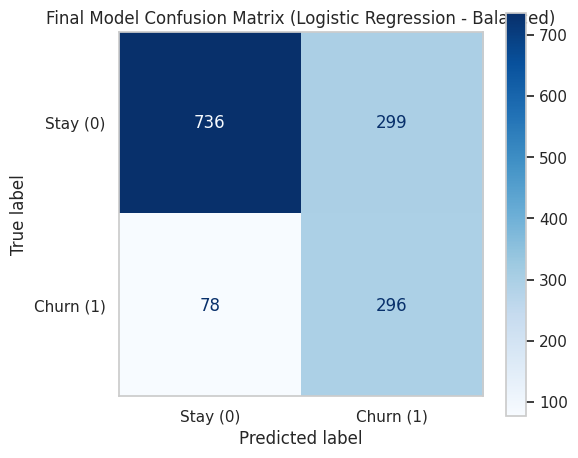


Final Classification Report:
              precision    recall  f1-score   support

    Stay (0)      0.904     0.711     0.796      1035
   Churn (1)      0.497     0.791     0.611       374

    accuracy                          0.732      1409
   macro avg      0.701     0.751     0.704      1409
weighted avg      0.796     0.732     0.747      1409



In [68]:
final_test_pred = final_model.predict(X_test)
cm = confusion_matrix(y_test, final_test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print(f"Confusion Matrix Values:")
print(f"True Negatives (TN):  {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP):  {tp}\n")

# 3. رسم مصفوفة الارتباك بصرياً
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Stay (0)", "Churn (1)"]
)
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Final Model Confusion Matrix (Logistic Regression - Balanced)")
plt.grid(False)
plt.tight_layout()
plt.show()

# 4. تقرير التصنيف النهائي
print("\nFinal Classification Report:")
print(
    classification_report(
        y_test,
        final_test_pred,
        target_names=["Stay (0)", "Churn (1)"],
        digits=3,
    )
)

## 26. Confusion Matrix & Business Context (TP, FP, TN, FN)

Based on the final tuned Logistic Regression model on the held-out test set ($N = 1,409$):

* **True Positives (TP = 296):** Customers who actually churned and were correctly identified by the model. This is the primary business value, allowing proactive intervention with targeted retention offers.
* **False Positives (FP = 299):** Customers predicted to churn who actually stayed ("false alarms"). This leads to minor unnecessary marketing costs or discounts given to loyal customers.
* **True Negatives (TN = 736):** Customers who stayed and were correctly predicted to stay. No retention budget is wasted on them.
* **False Negatives (FN = 78):** Customers who churned but were missed by the model. This is the **most costly error** because the company loses recurring revenue and lifetime customer value without getting a chance to intervene.

27. Describe two important patterns or features, but do not assume correlation proves causation.

## 27. Important Patterns / Features (Correlation ≠ Causation)

1. **Contract Type:**
   * **Observed Pattern:** Month-to-month contract customers have a dramatically higher churn rate (**42.71%**) compared to one-year (**11.27%**) and two-year (**2.83%**) contracts.
   * **Correlation $\neq$ Causation:** Choosing a month-to-month plan does not inherently cause cancellation. Customers who anticipate short-term needs or are uncertain about service quality may naturally select flexible plans.

2. **Customer Tenure:**
   * **Observed Pattern:** Customers in their first year ($\le 12$ months) experience a high churn rate (**47.44%**), whereas long-tenured customers ($> 48$ months) churn at only **9.51%**.
   * **Correlation $\neq$ Causation:** Shorter tenure itself does not cause churn; it reflects early friction during setup, onboarding, or unmet initial expectations, whereas longer-tenure cohorts represent an already satisfied survivor pool.

28. Suggest two actions the business might take for customers at risk of leaving.

1. Incentivized Contract Upgrade Campaigns:

Proactively target high-risk month-to-month subscribers with tailored offers—such as a discounted rate for the first 3–6 months or complimentary feature upgrades (e.g., speed boost or streaming bundle)—in exchange for committing to an annual contract. This directly addresses the segment with the highest churn volume.

2. Proactive Early-Tenure Onboarding & Support:Implement dedicated customer success check-ins during the first $90$ days of service. Automatically trigger priority technical support or satisfaction surveys for new accounts experiencing speed drops or service tickets to resolve issues before the customer decides to cancel.

29. Explain at least two limitations

1. False Alarms and Precision Trade-Off:While tuning improved Recall to 78.3%, Precision settled around 50.4%, producing 288 False Positives. Offering expensive retention gifts or steep price cuts to these misclassified non-churners could unnecessarily erode profit margins.   
2. Class Imbalance:The dataset is inherently imbalanced (26.54% churned vs. 73.46% stayed). Training on skewed data required using class_weight='balanced' to prevent models from defaulting to the majority class. While this successfully boosted sensitivity toward churners, it inherently increases the false alarm rate.   
3. Data Static Nature & Lack of Real-Time Behavioral Metrics:The dataset represents a historical snapshot without real-time dynamic engagement data (such as recent network outages, competitor promotional pricing, or customer call-center sentiment transcripts). As customer behavior and market conditions evolve, model performance will degrade unless refreshed continuously with live data.

30. Finish with a short recommendation: Which model would you choose, and why?

**Recommended Model:** **Logistic Regression (tuned with $C=1.0$ and `class_weight='balanced'`)**

**Why:**
1. **Aligned with Business Priorities:** Catching churners is far more valuable than preventing low-cost outreach false alarms. The model caught **296 out of 374** actual churners (**79.1% Recall**), missing only 78.
2. **Interpretability & Production Readiness:** Unlike tree ensembles, Logistic Regression offers transparent, explainable feature weights for business stakeholders and runs with minimal compute overhead in production.